## Calving series methodology for Jakobshavn Isbrae ##

This notebook is the most up to date copy of deriving a calving time series for glacier Jakobshavn Isbrae in Greenland. 

This notebook develops a __calving time series__ using:
1. satellite-derived terminus positions
2. surface velocity near the terminnus, and 
3. different metrics of terminus change

Where __length change__, is measured along the centerline, a common proxy for average glacier retreat; and __area change__ is across the full width of the glacier, capturing along-terminus variability and asymmetric calving behavior.



#### 1. Set up notebook and load in data ####

In [3]:
# import libraries and packages
import os
import glob
import dask
import panel
import shapely
import rasterio
import pandas as pd
import xarray as xr
import numpy as np
import geopandas as gpd
import nisardev as nisar
import grimpfunc as grimp
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as mcm
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib import colors
import cmocean.cm as cm
from shapely.geometry import LineString, Polygon, Point
from shapely.affinity import translate
from shapely.ops import (split, polygonize_full, linemerge, unary_union,)
from dask.diagnostics import ProgressBar

# autoreload of modules
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
#set data paths
centerline_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/data/flowlines/glacier0001_iter03.shp"
centerline_extended_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/data/flowlines/jakobshavn_centreline_ss.shp"
terminus_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/data/MEaSUREs_0781/collated/JakbobshavnIsbraeTerminus.shp"
velocity_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/data/MEaSUREs_0766/JakobshavnIsbraeVelocitySeriesNew.nc"

#read in velocity 
velocity = xr.open_dataset(velocity_path)

#read in centerline + make sure coordinate system = EPSG:3413
    # centerline source: https://zenodo.org/records/4284715 
centerline = gpd.read_file(centerline_path)
centerline = centerline.to_crs("EPSG:3413")
centerline_shape = centerline.geometry.iloc[0]

# read in extended centerline
centerline_extended = gpd.read_file(centerline_extended_path)
centerline_extended = centerline_extended.to_crs("EPSG:3413")

# merge extended centerline into 1 geometry
c_merged = linemerge(unary_union(centerline_extended.geometry))
centerline_extended = gpd.GeoDataFrame(geometry=[c_merged], crs=centerline_extended.crs)
centerline_extended_shape = centerline_extended.geometry.iloc[0]

# fixing the order of the geometries bc apparently its possible to do it backwards! 
parts = list(centerline_extended_shape.geoms)
main = parts[2]
extension = parts[0]
coords = list(extension.coords)[::-1] + list(main.coords)
centerline_extended_shape = LineString(coords)
centerline_extended = gpd.GeoSeries([centerline_extended_shape], crs="EPSG:3413")

#sanity check for geospatial alignment
print(centerline.crs)
print(centerline_extended.crs)

#read in terminus
terminus = gpd.read_file(terminus_path)
terminus = terminus.to_crs("EPSG:3413")

#sanity check for geospatial alignment
print(terminus.crs)

EPSG:3413
EPSG:3413
EPSG:3413


In [5]:
#cleaning
terminus = terminus.rename(columns={"SourceDate": "Date", "Quality_Fl" : "Flag"}) #rename for simplicity
terminus["Date"] = pd.to_datetime(terminus["Date"]) #make sure it is in datetime 
terminus = terminus.sort_values(by = 'Date')
terminus.drop_duplicates(subset = ['Glacier_ID', 'Date'], keep = 'first') #drop duplicates

,Image_ID,Image_Tile,Date,Flag,Glacier_ID,geometry
3,SEN1_NSIDC_0723_V2_20150101_20150112,S1A_090_004012,2015-01-03,0,3,"LINESTRING (-188606.112 -2265922.891, -188399...."
4,SEN1_NSIDC_0723_V2_20150113_20150124,S1A_090_004187,2015-01-15,1,3,"LINESTRING (-188634.464 -2265910.404, -188629...."
5,SEN1_NSIDC_0723_V2_20150125_20150205,S1A_090_004362,2015-01-27,1,3,"LINESTRING (-186068.771 -2276605.242, -185814...."
6,SEN1_NSIDC_0723_V2_20150206_20150217,S1A_090_004537,2015-02-08,0,3,"LINESTRING (-184745.971 -2277111.477, -184132...."
17,SEN1_NSIDC_0723_V4_20150218_20150301,S1A_090_004712,2015-02-20,0,3,"LINESTRING (-185068.764 -2276846.893, -184507...."
...,...,...,...,...,...,...
351,SEN1_NSIDC_0723_V4_20211125_20211130,S1A_090_040762,2021-11-27,0,3,"LINESTRING (-185111.097 -2276688.143, -184878...."
352,SEN1_NSIDC_0723_V4_20211201_20211206,S1B_090_029866,2021-12-03,1,3,"LINESTRING (-185164.014 -2276666.976, -184867...."
353,SEN1_NSIDC_0723_V4_20211207_20211212,S1A_090_040937,2021-12-09,1,3,"LINESTRING (-184931.18 -2276910.393, -184380.8..."
354,SEN1_NSIDC_0723_V4_20211213_20211218,S1B_090_030041,2021-12-15,1,3,"LINESTRING (-184793.596 -2276973.893, -184497...."


In [6]:
# nan color for plotting
c_nan = "#E7E7E7CC"

# consistent names and properties for data sources
dataprops = dict(
    velocity=dict(name="Velocity", color="#1f3a5f", linestyle="solid"),
    terminus=dict(name="Observed Terminus", linestyle="solid", linewidth=0.5, cmap=mpl.colormaps["Blues"],),
    predicted_terminus=dict(name="Predicted Terminus", color="#1f3a5f", linestyle="dashed", linewidth=1),
    centerline=dict(name="Centerline", color="#1f3a5f", linestyle="solid", linewidth=1),
    glacier_box = dict(name = "Glacier Box", color = "black", linestyle= "solid", linewidth = 1), 
    modified_glacier_box = dict(name = "Modified Glacier Box", color = "darkred", linestyle = "solid", linewidth = 1), 
    reference_box = dict(name = "Reference Box", color = "gray", linestyle = "dashed", linewidth = 1),     
)

# consistent names and properties for variables
varprops = dict(
    velocity=dict(name="velocity", short_name="velocity", variable_name="vel_up_centreline", units=r"m a$^{-1}$", cmap=mpl.colormaps["Blues_r"],),
    vx=dict(name="x-component of velocity", short_name=r"$v_x$", variable_name="vx_up_centerline", units=r"m a$^{-1}$", cmap=cm.balance,),
    vy=dict(name="y-component of velocity", short_name=r"$v_y$", variable_name="vy_up_centerline", units=r"m a$^{-1}$", cmap=cm.balance,),
    terminus_position=dict(name="relative terminus position", short_name="terminus position", variable_name="Centerline_Length", units="m", cmap=None,),
    terminus_change=dict(name="terminus position change rate", short_name=r"$dL/dt$", variable_name="dLdt", units=r"m a$^{-1}$", cmap=None,),
    calving_length=dict(name="calving magnitude", short_name="calving", variable_name="calving_magnitude", units="m", cmap=None,),
    calving_area=dict(name="calving area", short_name="calving area", variable_name="calving_area_km2", units=r"km$^2$", cmap=None,),
    valid_count=dict(name="valid velocity observations", short_name="valid count", variable_name="valid_count", units="", cmap=mpl.colormaps["Blues"],),
    observed_terminus_position=dict(name="observed terminus position", short_name="observed position", variable_name="L", units="m",cmap=None,),
    expected_terminus_position=dict(name="expected terminus position", short_name="expected position", variable_name="L_expected", units="m", cmap=None,),
    terminus_position_residual=dict(name="expected minus observed terminus position", short_name="expected - observed", variable_name="expected_minus_observed", units="m", cmap=None,),
)

# consistent plotting properties
plotprops = dict(
    figsize=(10, 5),fontsize=14, titlesize=18, titleweight = "bold", labelsize=14, labelweight= "bold", ticksize=14, legendsize=8, linewidth=1, markersize=6, grid=True, alpha=0.25,
    #background colour for plots
    facecolor="#E7E7E7CC", 
    #map labels
    xlabel = "Easting [m]", ylabel = "Northing [m]",
    #scientific notation for axes
    map_scilimits=(6,6),
    )

# automatically create axis labels and color nan 
for v in varprops.values():
    # make a copy of each colormap and set NaNs to c_nan
    if v.get("cmap") is not None:
        v["cmap"] = v["cmap"].copy()
        v["cmap"].set_bad(c_nan)
    # make labels
    if v["units"]:
        v["label"] = f"{v['name'].capitalize()} [{v['units']}]"
        v["short_label"] = f"{v['short_name']} [{v['units']}]"
    else:
        v["label"] = v["name"].capitalize()
        v["short_label"] = v["short_name"]

##### 2. Data visualisation / spatial verification ####
*What does the velocity data look like? Are the centreline and terminus geometries aligned?* 


In these cells I want to inspect the spatial coverage of the valid velocity observations across all the data, this will be helpful in seeing how much valid velocity data I do have for my time series. 

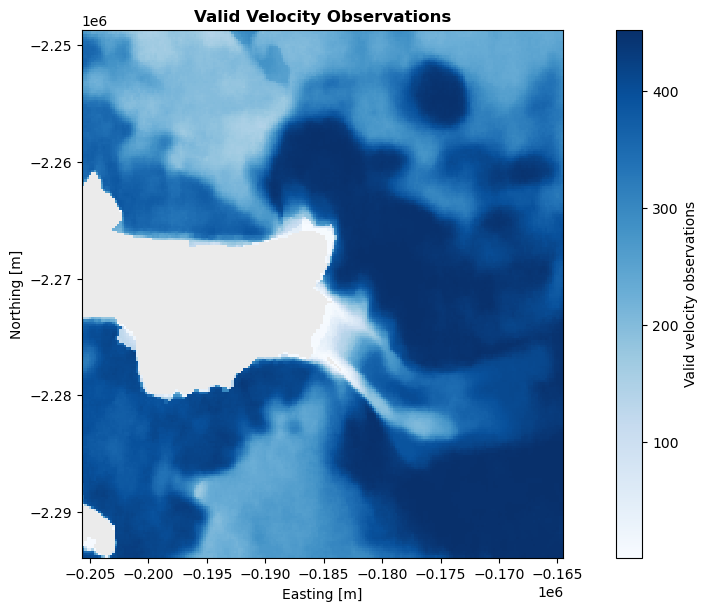

In [7]:
# prepapre velocity data for plotting
x_vals = velocity["x"].values
y_vals = velocity["y"].values

vel_band = (velocity["VelocityMap"].isel(band=2).assign_coords(x=("x", x_vals),  y=("y", y_vals),))
vel_times = pd.to_datetime(vel_band["time"].values)

# valid velocity counts
valid_count = vel_band.count(dim="time")
valid_count_plot = valid_count.where(valid_count > 0) #set 0 count to grey -- have it act as a NaN

# plotting properties for this variable
vprops = varprops["valid_count"]

# plot all time steps
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8,6),constrained_layout=True,)
valid_count_plot.plot(ax=ax, x="x", y="y", cmap=vprops["cmap"], add_colorbar=True, cbar_kwargs={"label": vprops["label"]})
ax.set_title("Valid Velocity Observations", fontweight=plotprops["titleweight"])
ax.set_xlabel(plotprops["xlabel"], )
ax.set_ylabel(plotprops["ylabel"])
ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
ax.set_aspect("equal")


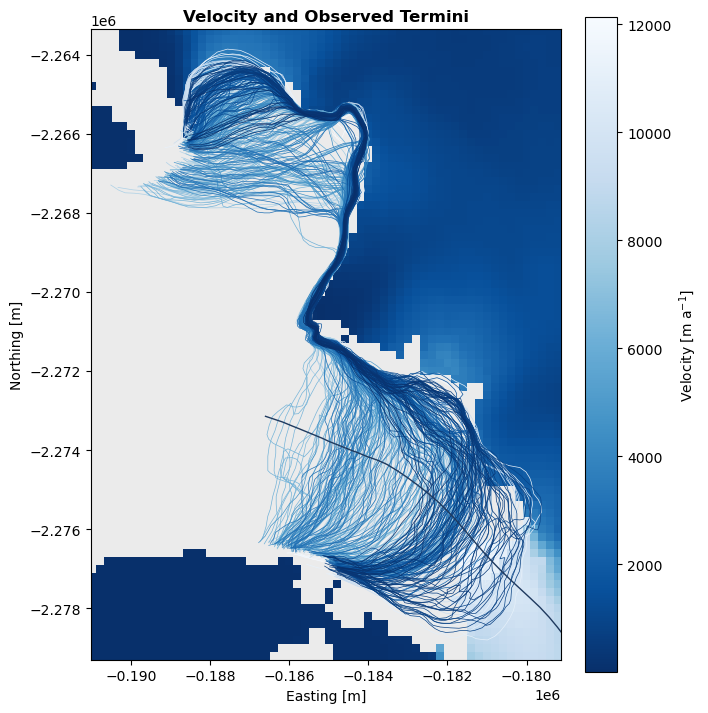

In [8]:
# prepare velocity data for plotting
x_vals = velocity["x"].values
y_vals = velocity["y"].values

vel_band = (velocity["VelocityMap"].isel(band=2).assign_coords(x=("x", x_vals),y=("y", y_vals),))
vel_times = pd.to_datetime(vel_band["time"].values)

# choose representative time index
sampletime = 220
vel_slice = vel_band.isel(time=sampletime)
sample_date = vel_times[sampletime]

# shorthand plotting properties
vprops = varprops["velocity"]
tprops = dataprops["terminus"]
clprops = dataprops["centerline"]
vel_cmap = vprops["cmap"].copy()
vel_cmap.set_bad(c_nan)
terminus_plot = terminus.sort_values("Date").copy()
date_norm = colors.Normalize(vmin=terminus_plot["Date"].min().value,vmax=terminus_plot["Date"].max().value,)
terminus_cmap = tprops["cmap"]

# plot velocity map with observed termini and extended centerline
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7,7),constrained_layout=True,)
# velocity map
vel = vel_slice.plot(ax=ax, x="x", y="y", cmap=vel_cmap, add_colorbar=True,cbar_kwargs={"label": vprops["label"]},)
# observed termini, coloured by date
for _, row in terminus_plot.iterrows():
    color = terminus_cmap(date_norm(row["Date"].value))
    gpd.GeoSeries([row.geometry],crs=terminus.crs,).plot(ax=ax,color=color,linewidth=tprops["linewidth"],linestyle=tprops["linestyle"],)
# extended centerline
centerline_extended.plot(ax=ax,color=clprops["color"],linewidth=clprops["linewidth"],linestyle=clprops["linestyle"],)

# zoom
xmin, ymin, xmax, ymax = terminus.total_bounds
zoom = 500
ax.set_xlim(xmin - zoom, xmax + zoom)
ax.set_ylim(ymin - zoom, ymax + zoom)
ax.set_aspect("equal")

ax.set_title(f"Velocity and Observed Termini", fontweight=plotprops["titleweight"])
ax.set_xlabel(plotprops["xlabel"])
ax.set_ylabel(plotprops["ylabel"])
ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
plt.show()

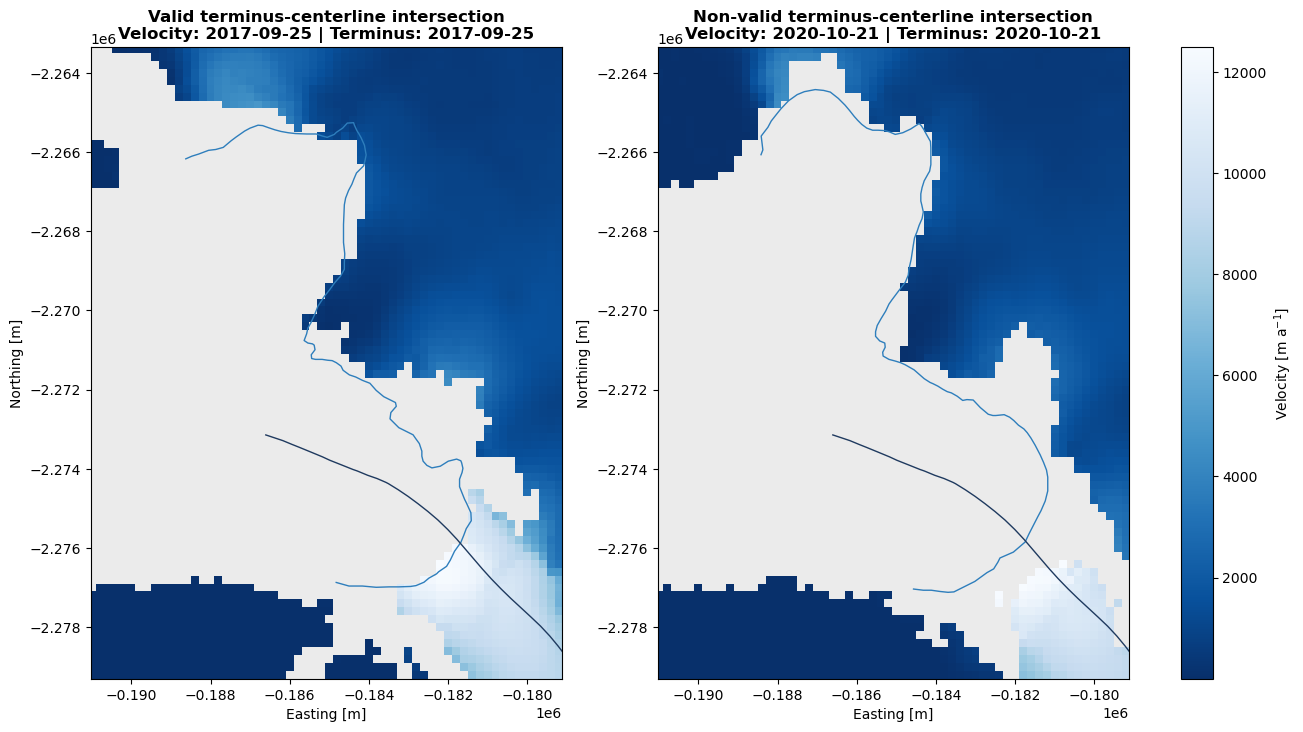

In [9]:
# TROUBLESHOOTING
# valid vs. non valid centerline intersections with terminus

# shorthand plotting properties
vprops = varprops["velocity"]
tprops = dataprops["terminus"]
clprops = dataprops["centerline"]

# sample time 1: valid intersection
# ---------------------------------------------------------------
sampletime1 = 113
vel_time1 = vel_band["time"].isel(time=sampletime1).values
nearest_time1 = (terminus["Date"] - vel_time1).abs().idxmin()
term_time1 = terminus.loc[[nearest_time1]]
vel_slice1 = vel_band.isel(time=sampletime1)
t_vel1 = pd.to_datetime(vel_time1)
t_term1 = term_time1["Date"].iloc[0]

# sample time 2: non-valid intersection
# ---------------------------------------------------------------
sampletime2 = 300
vel_time2 = vel_band["time"].isel(time=sampletime2).values
nearest_time2 = (terminus["Date"] - vel_time2).abs().idxmin()
term_time2 = terminus.loc[[nearest_time2]]
vel_slice2 = vel_band.isel(time=sampletime2)
t_vel2 = pd.to_datetime(vel_time2)
t_term2 = term_time2["Date"].iloc[0]

# plot
# ---------------------------------------------------------------

fig, ax = plt.subplots(1,2, figsize=(13, 7),constrained_layout=True,)

# valid intersection
vel = vel_slice1.plot(ax=ax[0],x="x",y="y",cmap=vprops["cmap"], add_colorbar=False)
term_time1.plot(ax=ax[0],facecolor="none",edgecolor=tprops["cmap"](0.7),linewidth=1,)
centerline_extended.plot(ax=ax[0],color=clprops["color"], linewidth=clprops["linewidth"], linestyle=clprops["linestyle"],)
ax[0].set_title(f"Valid terminus-centerline intersection\n"f"Velocity: {t_vel1:%Y-%m-%d} | Terminus: {t_term1:%Y-%m-%d}", fontweight=plotprops["titleweight"])

# non-valid intersection
vel_slice2.plot(ax=ax[1], x="x", y="y", cmap=vprops["cmap"], add_colorbar=False)
term_time2.plot(ax=ax[1], facecolor="none", edgecolor=tprops["cmap"](0.7), linewidth=1)
centerline_extended.plot(ax=ax[1], color=clprops["color"], linewidth=clprops["linewidth"], linestyle=clprops["linestyle"])
ax[1].set_title(f"Non-valid terminus-centerline intersection\n"f"Velocity: {t_vel2:%Y-%m-%d} | Terminus: {t_term2:%Y-%m-%d}", fontweight=plotprops["titleweight"])

xmin, ymin, xmax, ymax = terminus.total_bounds
zoom = 500

for a in ax:
    a.set_xlim(xmin - zoom, xmax + zoom)
    a.set_ylim(ymin - zoom, ymax + zoom)
    a.set_xlabel(plotprops["xlabel"])
    a.set_ylabel(plotprops["ylabel"])
    a.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
    a.set_aspect("equal")

# one shared colorbar
cbar = fig.colorbar(vel,ax=ax)
cbar.set_label(vprops["label"])

plt.show()

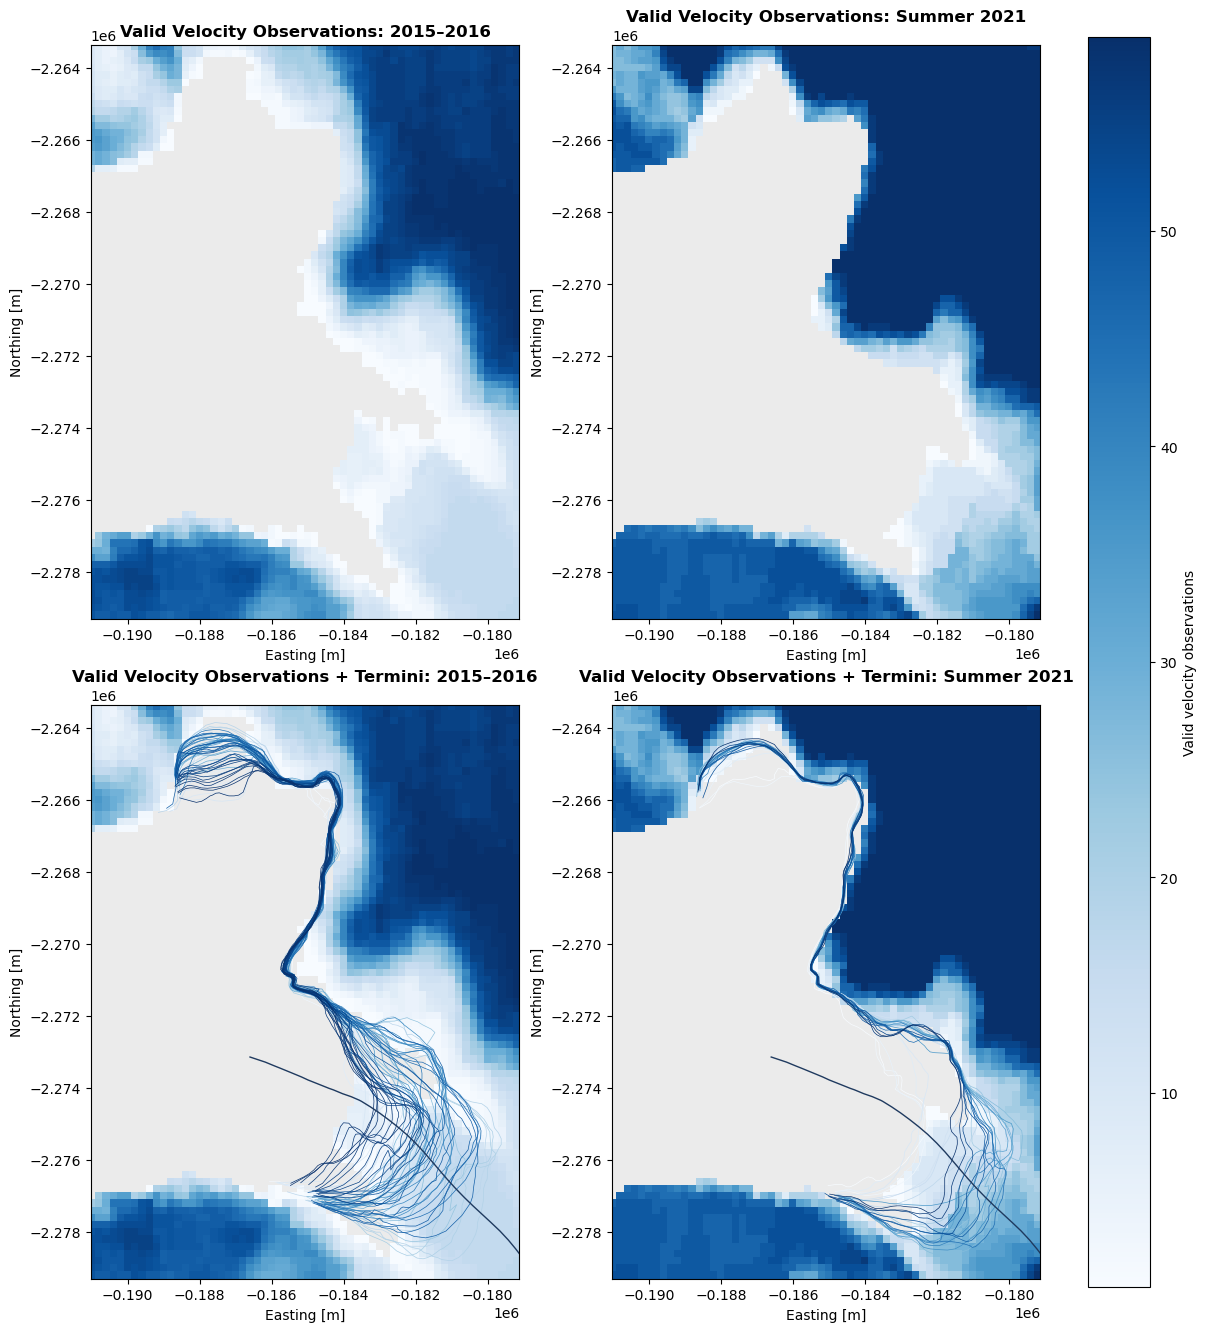

In [10]:
# TROUBLESHOOTING
# Velocity coverage + terminus positions

# shorthand plotting properties
vprops = varprops["valid_count"]
tprops = dataprops["terminus"]
clprops = dataprops["centerline"]

#velocity count
valid_count_2015_2016 = (vel_band.sel(time=slice("2015-01-01", "2016-12-31")).count(dim="time"))
valid_count_2015_2016_plot = valid_count_2015_2016.where(valid_count_2015_2016 > 0) #set 0 count to grey -- have it act as NaN
valid_count_2021 = (vel_band.sel(time=slice("2021-04-01", "2021-08-31")).count(dim="time"))
valid_count_2021_plot = valid_count_2021.where(valid_count_2021 > 0)

# terminus subsets
    # 2015 - 2016
    # Summer 2021 

term_2015_2016 = terminus[(terminus["Date"] >= "2015-01-01")& (terminus["Date"] <= "2016-12-31")].copy()
term_2021 = terminus[(terminus["Date"] >= "2021-04-01") & (terminus["Date"] <= "2021-08-31")].copy()

# convert dates to numeric values for plotting with geopandas
term_2015_2016["date_num"] = mdates.date2num(term_2015_2016["Date"])
term_2021["date_num"] = mdates.date2num(term_2021["Date"])

#plot
#---------------------------------------------------------------
fig, ax = plt.subplots(2,2,figsize=(12, 13),constrained_layout=True,)

#[0,0] valid velocity count 2015–2016
vel_count = valid_count_2015_2016_plot.plot(ax=ax[0, 0],x="x",y="y",cmap=vprops["cmap"],add_colorbar=False,)
ax[0, 0].set_title("Valid Velocity Observations: 2015–2016", fontweight=plotprops["titleweight"])

#[0,1] valid velocity count summer 2021
valid_count_2021_plot.plot(ax=ax[0, 1],x="x", y="y", cmap=vprops["cmap"], add_colorbar=False,)
ax[0, 1].set_title("Valid Velocity Observations: Summer 2021", fontweight=plotprops["titleweight"])

# [1,0] valid velocity count + termini 2015–2016
valid_count_2015_2016_plot.plot(ax=ax[1, 0], x="x", y="y", cmap=vprops["cmap"], add_colorbar=False,)
term_2015_2016.plot(ax=ax[1, 0], column="date_num", cmap=tprops["cmap"],linewidth=tprops["linewidth"],legend=False,)
centerline_extended.plot(ax=ax[1, 0],color=clprops["color"],linewidth=clprops["linewidth"],linestyle=clprops["linestyle"],)
ax[1, 0].set_title("Valid Velocity Observations + Termini: 2015–2016", fontweight=plotprops["titleweight"])

# [1,1] valid velocity count + termini summer 2021
valid_count_2021_plot.plot(ax=ax[1, 1],x="x", y="y", cmap=vprops["cmap"], add_colorbar=False,)
term_2021.plot(ax=ax[1, 1], column="date_num", cmap=tprops["cmap"], linewidth=tprops["linewidth"], legend=False,)
centerline_extended.plot(ax=ax[1, 1], color=clprops["color"], linewidth=clprops["linewidth"], linestyle=clprops["linestyle"],)
ax[1, 1].set_title("Valid Velocity Observations + Termini: Summer 2021", fontweight=plotprops["titleweight"])

xmin, ymin, xmax, ymax = terminus.total_bounds
zoom = 500

for a in ax.flat:
    a.set_xlim(xmin - zoom, xmax + zoom)
    a.set_ylim(ymin - zoom, ymax + zoom)
    a.set_xlabel(plotprops["xlabel"])
    a.set_ylabel(plotprops["ylabel"])
    a.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"]) 
    a.set_aspect("equal")

# one shared colorbar
cbar = fig.colorbar(vel_count,ax=ax)
cbar.set_label(vprops["label"])

plt.show()

### Step 1: Finding centerline and terminus intersection 

In [11]:
# finding the intersection between the centerline and the terminus
def intersection(centerline, terminus_line):
    intersect = centerline.intersection(terminus_line)

    if intersect.is_empty:
        return None

    if intersect.geom_type == "MultiPoint": #if there is more than one intersect put the point closes to the center of the terminus line
        return min(intersect.geoms, key = lambda p: p.distance(terminus_line.centroid))
    
    return intersect
 
pts = []
for i in range(len(terminus)):
    terminus_line = terminus.geometry.iloc[i]
    pt = intersection(centerline_extended_shape, terminus_line) #geometric intersection between centerline_shape and terminus_line 
    pts.append(pt)

terminus["intersect_points"] = pts

#check to see how many are NaN (i.e. no valid intersection)
none_vals = terminus["intersect_points"].isna().sum()
print(f"Number of NaN intersection points: {none_vals}")

#check to see how many are non NaN (i.e. valid intersection)
valid_vals = terminus["intersect_points"].notna().sum()
print(f"Number of valid intersection points: {valid_vals} out of {len(terminus)}")


Number of NaN intersection points: 0
Number of valid intersection points: 357 out of 357


### Step 2: Sample velocity at X m away from the intersection
- Using a consistent simple velocity extraction method
- As a comparison add a list that is velocity at intersection
- __Edit: If NaN at 1500m, then sample at 2000m, if still NaN then skip__

In [12]:
upstream_m = 1500

vel_at_intersection = []
vel_up_centerline = []

for i in range(len(terminus)):
    pt = terminus["intersect_points"].iloc[i]
    t_term = pd.to_datetime(terminus["Date"].iloc[i])

    if pt is None:
        vel_at_intersection.append(np.nan)
        vel_up_centerline.append(np.nan)
        continue

    vel_slice = vel_band.sel(time=t_term, method="nearest")

    # velocity at intersection
    v0 = vel_slice.sel(x=pt.x, y=pt.y, method="nearest").values
    vel_at_intersection.append(float(v0) if np.isfinite(v0) else np.nan)

    # velocity upstream along the same extended centerline
    d0 = centerline_extended_shape.project(pt)

    v1 = np.nan

    for upstream_m in [1500, 2000]:
        d1 = d0 + upstream_m

        if d1 > centerline_extended_shape.length:
            continue
        p1 = centerline_extended_shape.interpolate(float(d1))
        v_test = vel_slice.sel(x=p1.x,y=p1.y,method="nearest").values

        if np.isfinite(v_test):
            v1 = float(v_test)
            break
    vel_up_centerline.append(v1)

terminus["vel_at_intersection"] = vel_at_intersection
terminus["vel_up_centerline"] = vel_up_centerline

In [13]:
# -- Optional Smoothing and interpolation of velocity upstream of the centerline intersection --
#smoothed and interpolated velocity upstream of the centerline intersection
#window = "12D"  # 12-day rolling window
#smoothing = terminus.set_index("Date")["vel_up_centreline"].sort_index()
#smoothed = smoothing.rolling(window=window, min_periods=1, center=True).mean()
#smoothed_interp = smoothed.interpolate(method="time", limit=5)
#terminus["vel_up_smoothed_interp"] = smoothed_interp.reindex(terminus["Date"]).to_numpy()

print(f"Number of valid values in vel_at_intersection: {terminus['vel_at_intersection'].notna().sum()} out of {len(terminus)}")
print(f"Number of valid values in vel_up_centerline: {terminus['vel_up_centerline'].notna().sum()} out of {len(terminus)}")
#print(f"Number of valid values in vel_up_smoothed_interp: {terminus['vel_up_smoothed_interp'].notna().sum()} out of {len(terminus)}")

Number of valid values in vel_at_intersection: 52 out of 357
Number of valid values in vel_up_centerline: 296 out of 357


Velocity: 2019-06-29 | Terminus: 2019-06-29
Velocity: 2020-01-25 | Terminus: 2020-01-25
Velocity: 2016-09-21 | Terminus: 2016-09-18


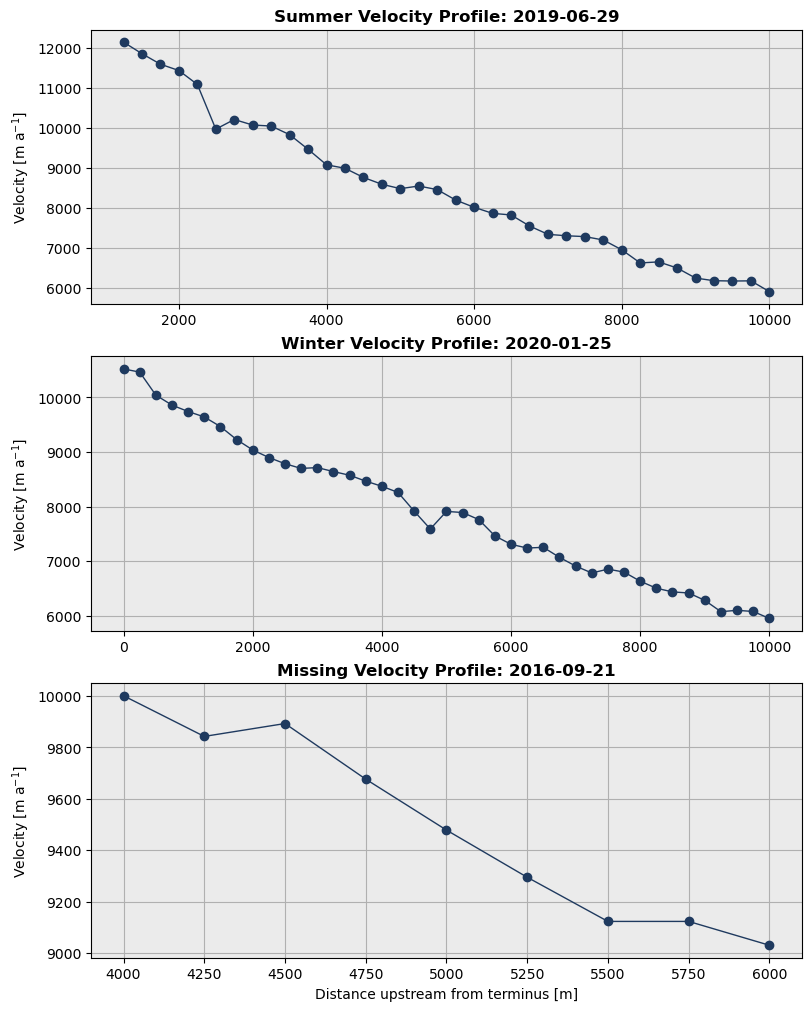

In [14]:
## TROUBLESHOOTING 
	# Take one date, and then take the velocity value from the terminus/centerline intersection
	# Keep shifting up 250 m increments up the centerline to around 10 000 m up to see the velocity profile

# shorthand plotting properties
vprops = varprops["velocity"]
dprops = dataprops["velocity"]

# distance upstream from terminus
dist_upstream = np.arange(0, 10000 + 250, 250)


# function to calculate velocity profile
# ---------------------------------------------------------------

def get_velocity_profile(sampletime):
    # velocity date and nearest terminus observation
    vel_time = pd.to_datetime(vel_band["time"].isel(time=sampletime).values)
    nearest_time = (terminus["Date"] - vel_time).abs().idxmin()
    # centerline intersection with terminus
    start = terminus.loc[nearest_time, "intersect_points"]
    start_dist = centerline_extended_shape.project(start)
    # sample points every 250 m upstream
    points = [ centerline_extended_shape.interpolate(start_dist + d) for d in dist_upstream]
    # velocity at selected time
    vel_slice = vel_band.isel(time=sampletime)
    # sample velocity at each point
    vel_profile = [vel_slice.sel(x=pt.x, y=pt.y, method="nearest").item()
        for pt in points
    ]

    print(f"Velocity: {vel_time:%Y-%m-%d} | " f"Terminus: {terminus.loc[nearest_time, 'Date']:%Y-%m-%d}")
    return vel_profile, vel_time


#sample dates for velocity profiles

samples = dict(
    summer=220,   # 2019-06-29
    winter=255,   # 2020-01-25
    missing=52,   # 2016-09-21
)

# plot velocity profiles
# ---------------------------------------------------------------

fig, ax = plt.subplots(3, 1, figsize=(8, 10), constrained_layout=True)

for velocity_profile, (season, sampletime) in zip(ax, samples.items()):
    vel_profile, vel_time = get_velocity_profile(sampletime)
    velocity_profile.plot(dist_upstream, vel_profile, color=dprops["color"], linestyle=dprops["linestyle"], linewidth=plotprops["linewidth"], marker="o", markersize=plotprops["markersize"])
    velocity_profile.set_title(f"{season.capitalize()} Velocity Profile: {vel_time:%Y-%m-%d}", fontweight=plotprops["titleweight"])
    velocity_profile.set_ylabel(vprops["label"])
    velocity_profile.grid(plotprops["grid"])

ax[-1].set_xlabel("Distance upstream from terminus [m]")

for a in ax:
    a.set_facecolor(plotprops["facecolor"])

plt.show()

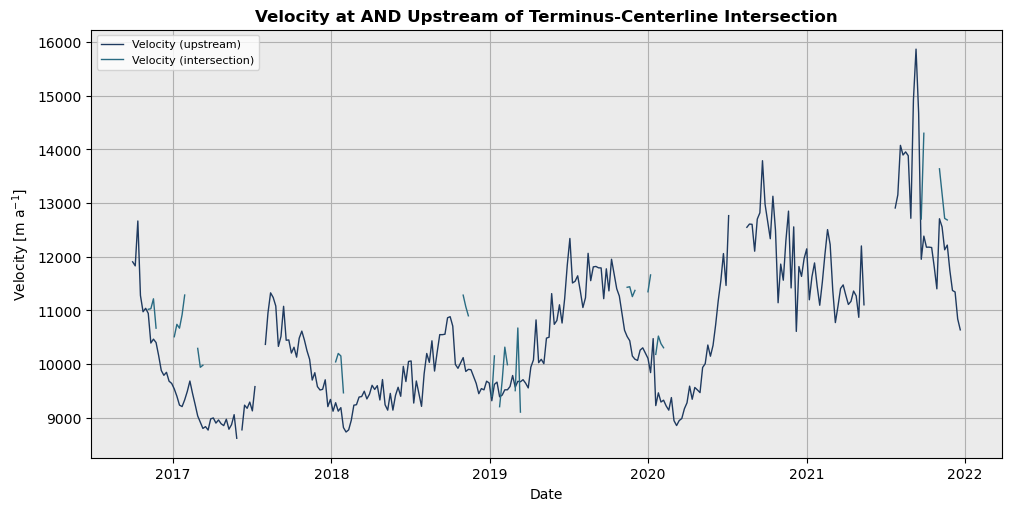

In [15]:
# plot velocity at intersection versus. upstream
# -------------------------------------------------

# shorthand plotting properties
vprops = varprops["velocity"]
dprops = dataprops["velocity"]

fig, ax = plt.subplots(figsize=(10,5), constrained_layout=True)

# velocity upstream
ax.plot(terminus["Date"], terminus["vel_up_centerline"], label="Velocity (upstream)", color=dprops["color"], linestyle=dprops["linestyle"], linewidth=plotprops["linewidth"])
# velocity at terminus-centerline intersection
ax.plot(terminus["Date"], terminus["vel_at_intersection"], label="Velocity (intersection)", color="#296B82", linestyle="solid", linewidth=plotprops["linewidth"])
ax.set_xlabel("Date")
ax.set_ylabel(vprops["label"])
ax.set_title("Velocity at AND Upstream of Terminus-Centerline Intersection", fontweight = "bold")
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"])
ax.legend(fontsize=plotprops["legendsize"])
plt.show()

For each terminus position:
1. Use the centerline-terminus intersection point
2. Get the length of the upstream segment 

This is Taryn's code - slightly modified

In [16]:
def get_centerline_length(terminus, centerline_extended):
    # ensure terminus data type
    if type(terminus) is LineString:
        pass
    if type(terminus) is pd.Series: #if pd take intersection point (from row)
        pt = terminus["intersect_points"]
    elif type(terminus) is gpd.GeoSeries: # if geoseries take single intersection point (from row)
        pt = terminus["intersect_points"].item()
    else: #if else assume it's already a point geometry
        pt = terminus

#same as tayrns code 
    if type(centerline_extended) is LineString:
        pass
    elif type(centerline_extended) is pd.Series:
        centerline_extended = centerline_extended.geometry
    elif type(centerline_extended) is gpd.GeoSeries:
        centerline_extended = centerline_extended.item()

    if pt is None: #if no valid intersection point return nan
        return np.nan
    
    try:
        d = centerline_extended.project(pt) #distance along the centreline from start to the intersection point
        centerline_length = centerline_extended.length - d

    except:
        centerline_length = np.nan #if anything fails (bad geometry, etc.) return nan

    return centerline_length

# calculate glacier length at centerline for each terminus
terminus["Centerline_Length"] = terminus.apply(get_centerline_length, axis = 1, centerline_extended=centerline_extended_shape)
terminus = terminus[terminus["Centerline_Length"].notna()].copy()

# use the first valid terminus as a baseline
terminus["Centerline_Length"] -= terminus["Centerline_Length"].iloc[0]

In [17]:
# def get_centerline_length(terminus, centerline):
#     # ensure terminus data type
#     if type(terminus) is LineString:
#         pass
#     elif type(terminus) is pd.Series:
#         terminus = terminus.geometry
#     elif type(terminus) is gpd.GeoSeries:
#         terminus = terminus.item()
#     # ensure centerline data type
#     if type(centerline) is LineString:
#         pass
#     elif type(centerline) is pd.Series:
#         centerline = centerline.geometry
#     elif type(centerline) is gpd.GeoSeries:
#         centerline = centerline.item()
#     # split centerline where it intersects with terminus
#     # -- should return a GeometryCollection with two lines
#     # -- note: might want to add an if statement to check for
#     # -- multiple intersections first (unlikely, but possible
#     # -- and will give weird results if so)
#     centerline_parts = shapely.ops.split(geom=centerline, splitter=terminus)
#     try:
#         centerline_upstream = centerline_parts.geoms[1] # <-- index=1 is an assumption! Not sure if it always works - it's probably based on order of coords in centerline
#         centerline_length = centerline_upstream.length
#     except: # <-- if terminus doesn't intersect centerline
#         # centerline_length = pd.NA
#         centerline_length = np.nan
#     return centerline_length

# # calculate glacier length at centerline for each terminus
# terminus["Centerline_Length"] = terminus.apply(get_centerline_length, axis=1, centerline=centerline_shape)
# terminus = terminus[terminus["Centerline_Length"].notna()].copy()

# # use the first valid terminus as a baseline
# terminus["Centerline_Length"] -= terminus["Centerline_Length"].iloc[0]

Calculating the difference between expected position (L_expected) and observed position (L):
- Using the the centerline length calculate the expected position based on the previous position
    - i.e., Expected position at time (t) based on the previous position + previous velocity (v) * elapsed time (dt)

In [18]:
# observed terminus position
terminus["L"] = terminus["Centerline_Length"]

# time step
terminus["dt_days"] = terminus["Date"].diff().dt.days
terminus["dt_years"] = terminus["dt_days"] / 365.25

# observed change in terminus position
terminus["dL"] = terminus["L"].diff()
terminus["dLdt"] = terminus["dL"] / terminus["dt_years"]

# expected position at t based on previous position + previous velocity * elapsed time
terminus["L_expected"] = (terminus["L"].shift(1) + terminus["vel_up_centerline"].shift(1) * terminus["dt_years"])

# difference between expected and observed position
terminus["expected_minus_observed"] = terminus["L_expected"] - terminus["L"]

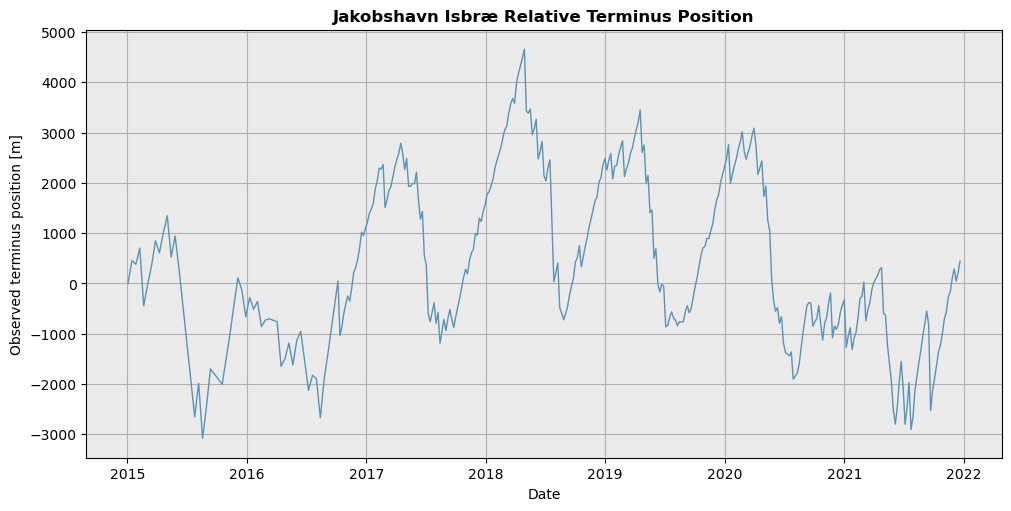

In [19]:
# relative terminus position through time

# shorthand plotting properties
tprops = varprops["observed_terminus_position"]

fig, ax = plt.subplots(figsize=(10,5),constrained_layout=True)
ax.plot(terminus["Date"], terminus[tprops["variable_name"]], linewidth=plotprops["linewidth"], color ="#5c93b3" )
ax.set_title("Jakobshavn Isbræ Relative Terminus Position", weight ="bold")
ax.set_xlabel("Date")
ax.set_ylabel(tprops["label"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"])
plt.show()

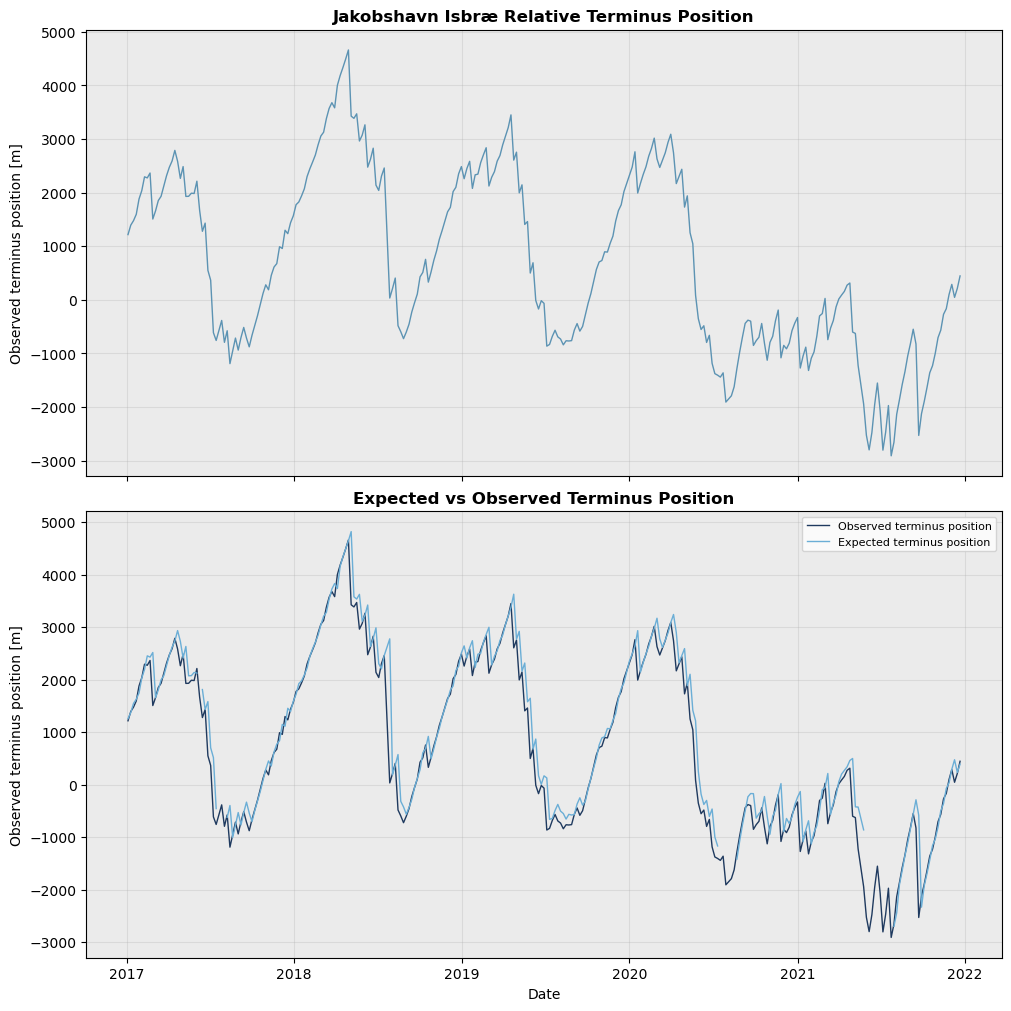

In [20]:
# relative terminus positions and observed vs. predicted

# shorthand plotting properties
tprops = varprops["observed_terminus_position"]
exprops = varprops["expected_terminus_position"]

# cut to 2017 because of limited velocity data before then
terminus_plot = terminus[terminus["Date"] >= "2017"].copy()

fig, ax = plt.subplots(2,1, figsize=(10, 10), constrained_layout=True, sharex=True)

# jakobshavn relative terminus posotion
# --------------------------------------------------------------
ax[0].plot(terminus_plot["Date"], terminus_plot[tprops["variable_name"]], linewidth=plotprops["linewidth"], color="#5c93b3")
ax[0].set_title("Jakobshavn Isbræ Relative Terminus Position", fontweight = "bold")
ax[0].set_ylabel(tprops["label"])
ax[0].set_facecolor(plotprops["facecolor"])
ax[0].grid(plotprops["grid"], alpha=0.3)

# expected vs observed terminus position
# ---------------------------------------------------------------
ax[1].plot(terminus_plot["Date"], terminus_plot[tprops["variable_name"]], linewidth=plotprops["linewidth"], color="#1f3a5f",label=tprops["name"].capitalize())
ax[1].plot(terminus_plot["Date"],terminus_plot[exprops["variable_name"]],linewidth=plotprops["linewidth"],color="#6baed6",label=exprops["name"].capitalize())
ax[1].set_title("Expected vs Observed Terminus Position", fontweight = "bold")
ax[1].set_xlabel("Date")
ax[1].set_ylabel(tprops["label"])
ax[1].set_facecolor(plotprops["facecolor"])
ax[1].grid(plotprops["grid"], alpha=0.3)
ax[1].legend(fontsize=plotprops["legendsize"])
plt.show()

Calculate the magnitude of calving events, where __calving = velocity x dt - dL__

__Calving events are positive__:
- dLdt > 0 means length is increasing with time - i.e., advance 
- dLdT < 0 means length is decreasing with time - i.e., retreat
    - according to plot dLdt is primarily negative
- vel > 0 flowing towards terminus 

So calving = positve value - negative value, therefore, __calving is positive__ 

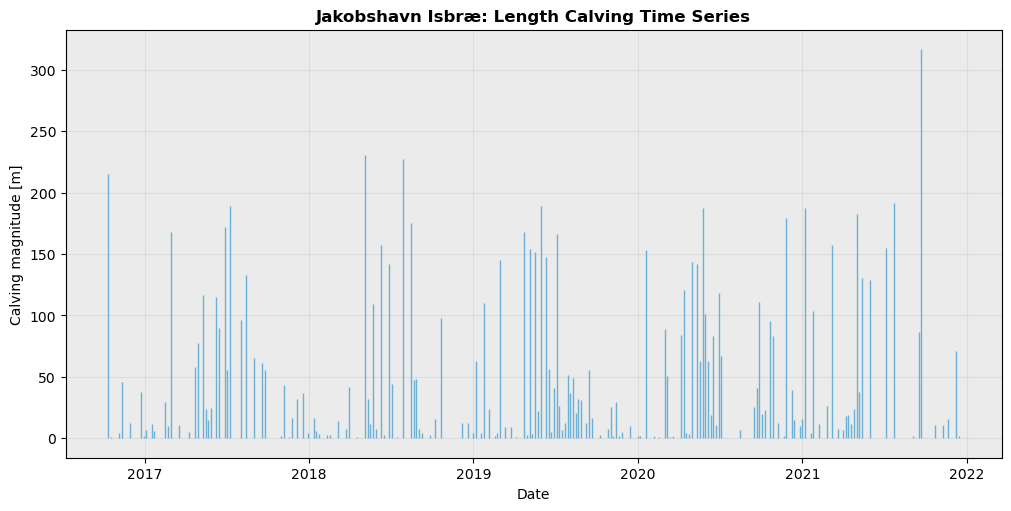

In [21]:
terminus["calving"] = terminus["vel_up_centerline"] - terminus["dLdt"]
terminus["calving_magnitude"] = terminus["calving"]/365.25

#calving time series

# shorthand plotting properties
cprops = varprops["calving_length"]

# mask negative values
terminus["calving_positive"] = (terminus["calving_magnitude"].where(terminus["calving_magnitude"] > 0))

# plot calving magnitudes
# -------------------------------------
fig, ax = plt.subplots(figsize=(10,5),constrained_layout=True)
ax.vlines(terminus["Date"],ymin=0,ymax=terminus["calving_positive"],linewidth=plotprops["linewidth"],color="#6baed6")
ax.set_title("Jakobshavn Isbræ: Length Calving Time Series", fontweight = "bold")
ax.set_xlabel("Date")
ax.set_ylabel(cprops["label"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"], alpha=0.25)
plt.show()

In [22]:
calving_time_series= terminus[["Date", "vel_up_centerline","dLdt","calving","calving_magnitude","dt_days","dt_years", "Centerline_Length"]].copy()
output_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/Jakobshavn-Isbrae-CalvingStatistics/jakobshavn_calving_length_ts.csv"
calving_time_series.to_csv(output_path, index=False)

#### Step 4: Area change calving time series ####
1. Use centerline velocity to begin with, 
2. Look at how velocity varies along the terminus!

Note: Added modified glacier box size - because I just want to look at the lower trunk bit of JI (where I have the centerline)

In [23]:
#path & read
box_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/data/MEaSUREs_0781/glacier_boxes_v01.0.shp"
mod_box_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/data/MEaSUREs_0781/ji_box_mod.shp"

box = gpd.read_file(box_path)
box = box.to_crs("EPSG:3413")
ji_mod_box = gpd.read_file(mod_box_path)
ji_mod_box = ji_mod_box.to_crs("EPSG:3413")

#jakobshavn box
ji_box = box[box["Glacier_ID"] == 3]
print(ji_box.crs)
print(ji_mod_box.crs)

# polygon geometry - just in case i need it
ji_box_polygon = ji_box.geometry.iloc[0]
ji_box_polygon = Polygon(ji_box_polygon)
ji_mod_box_polygon = ji_mod_box.geometry.iloc[0]
ji_mod_box_polygon = Polygon(ji_mod_box_polygon)

referencebox = ji_mod_box_polygon.boundary 

#check
print(ji_box.geom_type)
print(ji_box_polygon.geom_type) 
print(ji_mod_box.geom_type)
print(ji_mod_box_polygon.geom_type)

EPSG:3413
EPSG:3413
24    LineString
dtype: object
Polygon
0    LineString
dtype: object
Polygon


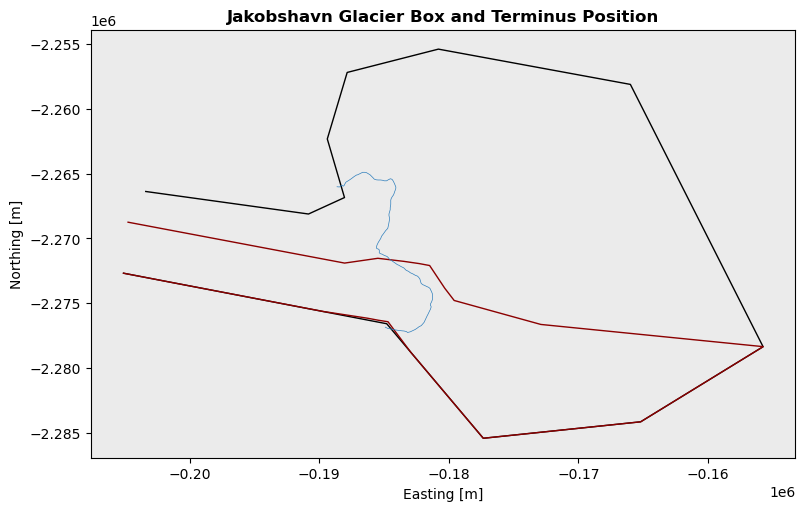

In [24]:

# shorthand plotting properties
bprops = dataprops["glacier_box"]
mbprops = dataprops["modified_glacier_box"]
tprops = dataprops["terminus"]

fig, ax = plt.subplots(figsize=plotprops["figsize"], constrained_layout=True,)

# original glacier box
ji_box.plot(ax=ax, color=bprops["color"], linestyle=bprops["linestyle"], linewidth=bprops["linewidth"])
# modified glacier box
ji_mod_box.plot(ax=ax, color=mbprops["color"], linestyle=mbprops["linestyle"], linewidth=mbprops["linewidth"])

# example terminus position
terminus.iloc[[100]].plot(ax=ax, color=tprops["cmap"](0.7), linewidth=tprops["linewidth"])

ax.set_title("Jakobshavn Glacier Box and Terminus Position",fontweight=plotprops["titleweight"])
ax.set_xlabel(plotprops["xlabel"])
ax.set_ylabel(plotprops["ylabel"])
ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
ax.set_aspect("equal")
ax.set_facecolor(plotprops["facecolor"])

plt.show()

### 4a. Extracting 'vx' and 'vy'
For now, I am going to use the 'vx' and 'vy' at the point where I got the 'vv' for the previous part from. Later, I can see if there is a better way to go about this!

In [25]:
# velocity data, 3 bands, 'vv', 'vx' and 'vy'
# so now i gotta extract the 'vx' and 'vy' at the point where i got the 'vv' 

print(velocity["band"].values)

#select vel bands - need vx, and vy for later translate fnction
vx_band = velocity["VelocityMap"].sel(band = 'vx')
vy_band = velocity["VelocityMap"].sel(band = 'vy')
vv_band = velocity["VelocityMap"].sel(band = 'vv')

# try just using the same velocity extraction method as before

vx_up_centerline = []
vy_up_centerline = []

for i in range(len(terminus)):
    pt = terminus["intersect_points"].iloc[i]
    t_term = pd.to_datetime(terminus["Date"].iloc[i])

    if pt is None:
        vx_up_centerline.append(np.nan)
        vy_up_centerline.append(np.nan)
        continue

    vx_slice = vx_band.sel(time=t_term, method="nearest")
    vy_slice = vy_band.sel(time=t_term, method="nearest")

    # velocity at intersection
    vx0 = vx_slice.sel(x=pt.x, y=pt.y, method="nearest").values
    vy0 = vy_slice.sel(x=pt.x, y=pt.y, method="nearest").values

    # velocity upstream along the same extended centreline
    d0 = centerline_extended_shape.project(pt)

    vx1 = np.nan
    vy1 = np.nan

    for upstream_m in [1500, 2000]: #try this again for consistency
        d1 = d0 + upstream_m

        if d1 > centerline_extended_shape.length:
            continue
        p1 = centerline_extended_shape.interpolate(float(d1))
        vx_test = vx_slice.sel(x=p1.x,y=p1.y,method="nearest").values
        vy_test = vy_slice.sel(x=p1.x,y=p1.y,method="nearest").values

        if np.isfinite(vx_test) and np.isfinite(vy_test):
            vx1 = float(vx_test)
            vy1 = float(vy_test)
            break
    vx_up_centerline.append(vx1)
    vy_up_centerline.append(vy1)

terminus["vx_up_centerline"] = vx_up_centerline
terminus["vy_up_centerline"] = vy_up_centerline

print(terminus[["vx_up_centerline", "vy_up_centerline"]].isna().sum())

['vx' 'vy' 'vv']
vx_up_centerline    61
vy_up_centerline    61
dtype: int64


<class 'shapely.geometry.polygon.Polygon'>
LineString
LineString


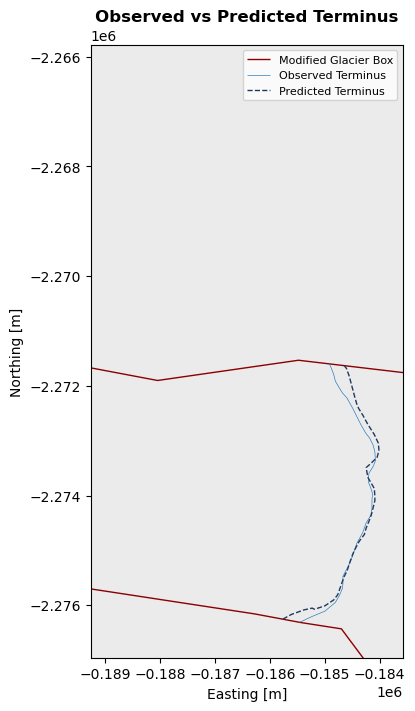

In [26]:
# test methodology cell 
# make predicted terminus lines:https://geopandas.org/en/latest/docs/reference/api/geopandas.GeoSeries.translate.html

#use random index for now 
t = 242

#observed terminus position
observed_line = terminus.geometry.iloc[t]
# previous terminus position
previous_line = terminus.geometry.iloc[t-1]

# time between observations  - dt
dt = terminus["dt_years"].iloc[t]

dx = terminus["vx_up_centerline"].iloc[t-1] * dt
dy = terminus["vy_up_centerline"].iloc[t-1] * dt

# predicted terminus line at current time
predicted_line = translate(previous_line, xoff=dx, yoff=dy)

# confine terminus lines to the box
observed_clipped = observed_line.intersection(ji_mod_box_polygon)
predicted_clipped = predicted_line.intersection(ji_mod_box_polygon)

print(type(ji_mod_box_polygon))
print(observed_clipped.geom_type)
print(predicted_clipped.geom_type)

# plot to verify
# ----------------------------------------
# shorthand plotting properties
bprops = dataprops["modified_glacier_box"]
oprops = dataprops["terminus"]
pprops = dataprops["predicted_terminus"]

fig, ax = plt.subplots(figsize=(5,7),constrained_layout=True,)

# modified glacier box
ji_mod_box.plot(ax=ax, color=bprops["color"], linestyle=bprops["linestyle"], linewidth=bprops["linewidth"], label=bprops["name"])
# observed terminus
gpd.GeoSeries([observed_clipped], crs=terminus.crs).plot(ax=ax, color=oprops["cmap"](0.7),linewidth=oprops["linewidth"], linestyle=oprops["linestyle"], label=oprops["name"])
# predicted terminus
gpd.GeoSeries([predicted_clipped], crs=terminus.crs).plot(ax=ax, color=pprops["color"], linewidth=pprops["linewidth"], linestyle=pprops["linestyle"], label=pprops["name"],)

# zoom
xmin, ymin, xmax, ymax = observed_line.bounds
zoom = 500
ax.set_xlim(xmin - zoom, xmax + zoom)
ax.set_ylim(ymin - zoom, ymax + zoom)
ax.set_aspect("equal")

ax.set_title( "Observed vs Predicted Terminus", fontweight=plotprops["titleweight"])
ax.set_xlabel(plotprops["xlabel"])
ax.set_ylabel(plotprops["ylabel"])
ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"],)
ax.set_facecolor(plotprops["facecolor"])
ax.legend(fontsize=plotprops["legendsize"])

plt.show()

### 4b. Finding the area between predicted and observed
For now, treat it as one big bulk polygon area as opposed to multiple sections. Splitting one polygon into multipolygons to identify the difference between bulk and smaller evemts

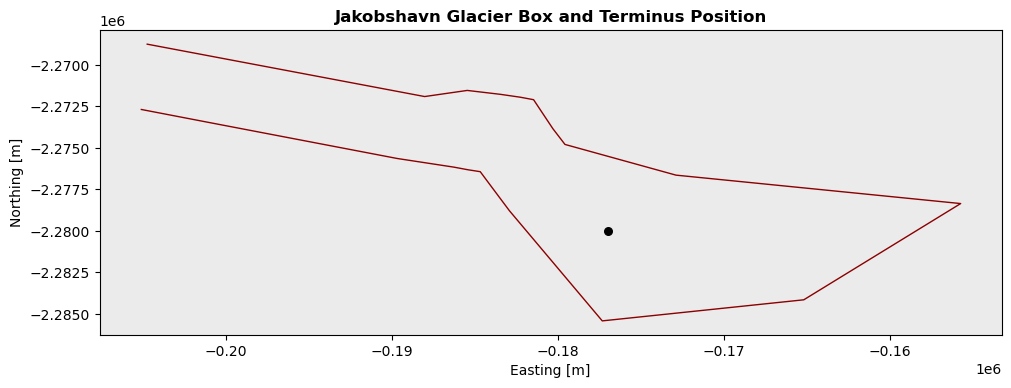

In [27]:
ice_point = Point(-177000, -2280000) # just putting this here so i know which side it glacier side each time

fig, ax = plt.subplots(figsize=plotprops["figsize"], constrained_layout=True,)
# modified glacier box
ji_mod_box.plot(ax=ax, color=mbprops["color"], linestyle=mbprops["linestyle"], linewidth=mbprops["linewidth"])
gpd.GeoSeries([ice_point]).plot(ax=ax, color="black",  markersize=30)

ax.set_title("Jakobshavn Glacier Box and Terminus Position",fontweight=plotprops["titleweight"])
ax.set_xlabel(plotprops["xlabel"])
ax.set_ylabel(plotprops["ylabel"])
ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
ax.set_aspect("equal")
ax.set_facecolor(plotprops["facecolor"])

plt.show()

In [28]:
terminus = terminus.reset_index(drop=True)

# wrapping test area into function 
def get_area_change(row, terminus, box_polygon, ice_point):

    terminus_index = row.name

    if terminus_index == 0:
        area_change = np.nan

    else: # same as test case above
        observed_line = row.geometry
        previous_line = terminus.geometry.iloc[terminus_index - 1]

        dx = terminus["vx_up_centerline"].iloc[terminus_index - 1] * row["dt_years"] # d = vt
        dy = terminus["vy_up_centerline"].iloc[terminus_index - 1] * row["dt_years"] # d = vt

        predicted_line = translate(previous_line, xoff=dx, yoff=dy)

        try: # split the glacier box with observed_line and predicted_line
            observed_split = split(box_polygon, observed_line)
            predicted_split = split(box_polygon, predicted_line)

            observed_polygon = list(observed_split.geoms) #geometry
            predicted_polygon = list(predicted_split.geoms) #geometry

            #ensure that observed/predicted glacier is on the correct side (using ice_point) 
            observed_glacier = [p for p in observed_polygon if p.contains(ice_point)][0]
            predicted_glacier = [p for p in predicted_polygon if p.contains(ice_point)][0]

            # derive calving area/polygon using shapely.difference
            calving_polygon = predicted_glacier.difference(observed_glacier)
            area_change = calving_polygon.area
            #area_change = predicted_glacier.area - observed_glacier.area

        except:
            area_change = np.nan

    return area_change

terminus["calving_area_m2"] = terminus.apply(get_area_change, axis=1, terminus=terminus, box_polygon=ji_mod_box_polygon, ice_point=ice_point)
terminus["calving_area_km2"] = terminus["calving_area_m2"] / 1e6

print(terminus["calving_area_km2"].notna().sum())


295


In [29]:
def get_calving_sections(row, terminus, box_polygon, ice_point):

    terminus_index = row.name

    if terminus_index == 0:
        return []

    observed_line = row.geometry
    previous_line = terminus.geometry.iloc[terminus_index - 1]

    dx = (terminus["vx_up_centerline"].iloc[terminus_index - 1] * row["dt_years"])
    dy = (terminus["vy_up_centerline"].iloc[terminus_index - 1] * row["dt_years"])

    predicted_line = translate(previous_line, xoff=dx, yoff=dy)

    try:
        observed_split = split(box_polygon, observed_line)
        predicted_split = split(box_polygon, predicted_line)

        observed_polygons = list(observed_split.geoms)
        predicted_polygons = list(predicted_split.geoms)

        observed_glacier = [p for p in observed_polygons if p.contains(ice_point)][0]
        predicted_glacier = [p for p in predicted_polygons if p.contains(ice_point)][0]

        calving_polygon = predicted_glacier.difference(observed_glacier)

        if calving_polygon.geom_type == "Polygon":
            calving_sections = [calving_polygon]

        elif calving_polygon.geom_type == "MultiPolygon":
            calving_sections = list(calving_polygon.geoms)

        else:
            calving_sections = []

        return calving_sections

    except:
        return []

terminus["calving_sections"] = terminus.apply(get_calving_sections, axis=1, terminus=terminus, box_polygon=ji_mod_box_polygon, ice_point=ice_point)
terminus["calving_sections_areas_km"] = terminus["calving_sections"].apply( lambda sections : [section.area / 1e6 for section in sections])
print(terminus["calving_sections"].notna().sum())
print(terminus["calving_sections_areas_km"].notna().sum())

357
357


In [35]:
def plot_calving(i):
    terminus_observed = terminus.geometry.iloc[i]
    terminus_previous = terminus.geometry.iloc[i - 1]

    dx = terminus["vx_up_centerline"].iloc[i - 1] * terminus["dt_years"].iloc[i]
    dy = terminus["vy_up_centerline"].iloc[i - 1] * terminus["dt_years"].iloc[i]

    predicted_line = translate(terminus_previous, xoff=dx, yoff=dy)

    try:
        observed_split = split(ji_mod_box_polygon, terminus_observed)
        predicted_split = split(ji_mod_box_polygon, predicted_line)

        observed_polygons = list(observed_split.geoms)
        predicted_polygons = list(predicted_split.geoms)

        observed_glacier = [p for p in observed_polygons if p.contains(ice_point)][0]
        predicted_glacier = [p for p in predicted_polygons if p.contains(ice_point)][0]

        calving_polygon = predicted_glacier.difference(observed_glacier)

    except:
        print("Calving geometry could NOT be calculated :(")
        return

    # split calving area into individual sections
    if calving_polygon.geom_type == "Polygon":
        calving_sections = [calving_polygon]

    elif calving_polygon.geom_type == "MultiPolygon":
        calving_sections = list(calving_polygon.geoms)

    else:
        calving_sections = []

    print("Number of calving sections:", len(calving_sections))

    for section_number, section in enumerate(calving_sections):
        print(f"{section.area:.2e} m²")

    print(f"Bulk area calved: {terminus['calving_area_m2'].iloc[i]:.2e} m²")

    observed_clipped = terminus_observed.intersection(ji_mod_box_polygon)
    predicted_clipped = predicted_line.intersection(ji_mod_box_polygon)

    #plotting props 
    oprops = dataprops["terminus"]
    pprops = dataprops["predicted_terminus"]
    bprops = dataprops["modified_glacier_box"]

    fig, ax = plt.subplots(figsize=(5, 7))

    for section in calving_sections:
        gpd.GeoSeries([section]).plot(ax=ax, color="pink", alpha=0.5)

    # observed terminus
    gpd.GeoSeries([observed_clipped], crs=terminus.crs).plot(ax=ax, color=oprops["cmap"](0.7),linewidth=oprops["linewidth"], linestyle=oprops["linestyle"], label=oprops["name"])
    # predicted terminus
    gpd.GeoSeries([predicted_clipped], crs=terminus.crs).plot(ax=ax, color=pprops["color"], linewidth=pprops["linewidth"], linestyle=pprops["linestyle"], label=pprops["name"])
    #gpd.GeoSeries([ji_mod_box_polygon]).boundary.plot(ax=ax, color="black")
    ji_mod_box.plot(ax=ax, color=bprops["color"], linestyle=bprops["linestyle"], linewidth=bprops["linewidth"], label=bprops["name"])

   # zoom
    xmin, ymin, xmax, ymax = observed_clipped.bounds
    zoom = 500
    ax.set_xlim(xmin - zoom, xmax + zoom)
    ax.set_ylim(ymin - zoom, ymax + zoom)
    ax.set_aspect("equal")

    # formatting
    date_title = terminus["Date"].iloc[i].strftime("%Y-%m-%d")
    ax.set_title(f"Observed vs Predicted Terminus: Area\n{date_title}", fontweight=plotprops["titleweight"])
    ax.set_xlabel(plotprops["xlabel"])
    ax.set_ylabel(plotprops["ylabel"])
    ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
    ax.set_facecolor(plotprops["facecolor"])
    ax.legend(fontsize=plotprops["legendsize"])
    plt.show()

    # total area directly from the calving polygon
    polygon_area = calving_polygon.area

## TROUBLESHOOTING difference between bulk area and the pink sections 
    # sum of all pink sections
    sections_area = sum(section.area for section in calving_sections)

    # area currently stored in terminus dataframe
    stored_area = terminus["calving_area_m2"].iloc[i]

    print(f"Calving polygon area: {polygon_area:.2e} m²")
    print(f"Sum of sections:      {sections_area:.2e} m²")
    print(f"Bulk area:          {stored_area:.2e} m²")

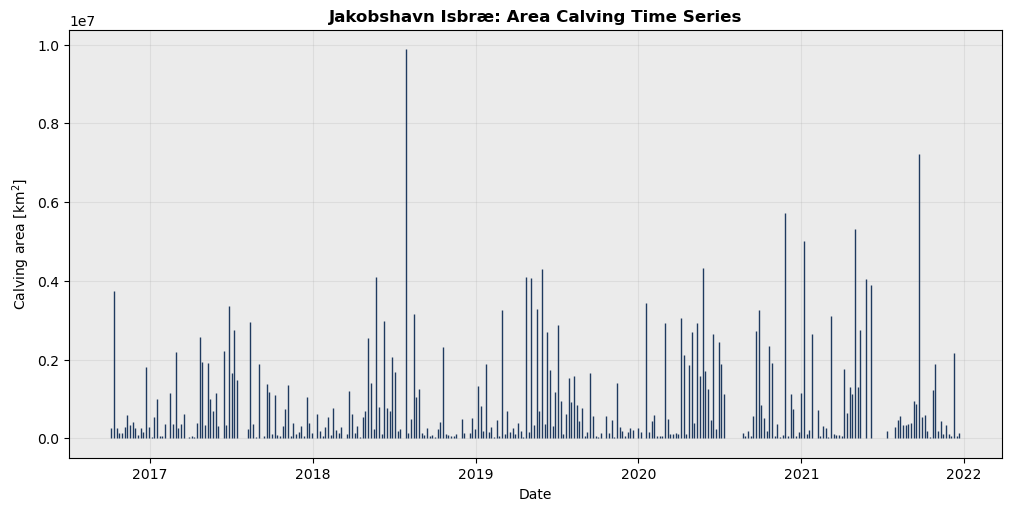

In [36]:
#calving area time series

#short hand plotting properties 
caprops = varprops["calving_area"]

#plot calving area magnitudes
fig, ax = plt.subplots(figsize=(10,5), constrained_layout = True)
ax.vlines(terminus["Date"], ymin = 0, ymax = terminus["calving_area_m2"],linewidth=plotprops["linewidth"], color="#1f3a5f")
ax.set_title("Jakobshavn Isbræ: Area Calving Time Series", fontweight = "bold")
ax.set_xlabel("Date")
ax.set_ylabel(caprops["label"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"], alpha=0.25)
plt.show()

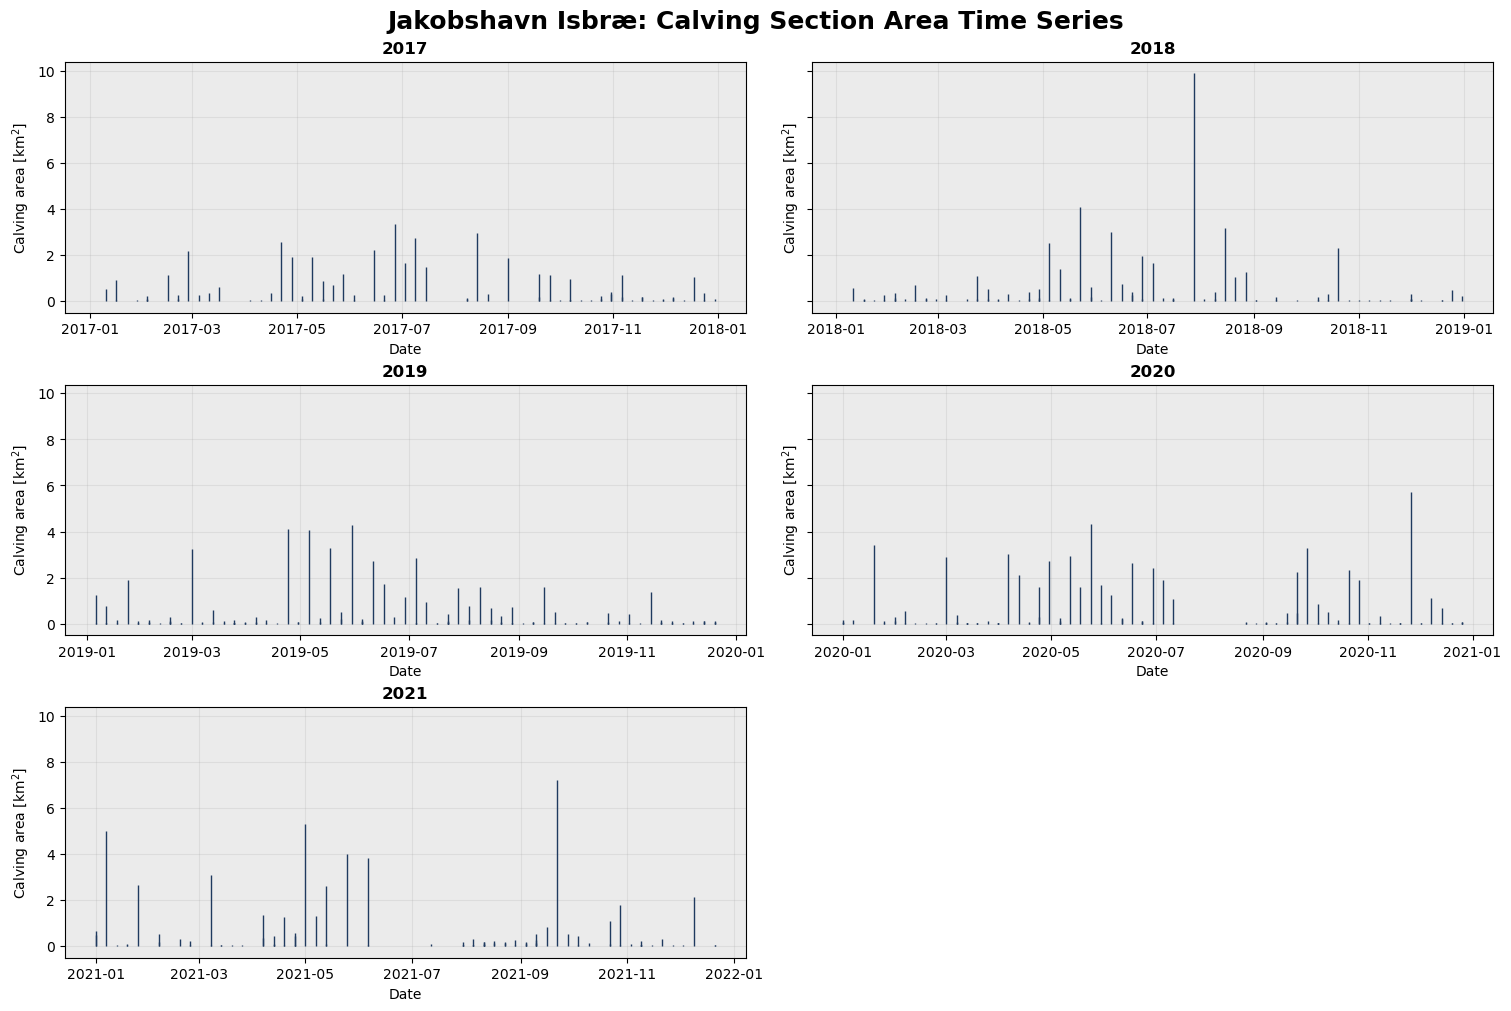

In [37]:
# calving (individual sections) area time series
# plot individual calving area sections in time intervals (2017-2018, 2018-2019, 2019-2020, 2020-2021, 2021-2022)


fig, ax = plt.subplots(3,2, figsize = (15,10), constrained_layout=True, sharey = True)

fig.suptitle("Jakobshavn Isbræ: Calving Section Area Time Series", fontweight=plotprops["titleweight"], fontsize=plotprops["titlesize"])

#2017-2018
terminus_2017 = terminus[(terminus["Date"] >= "2017-01-01") & (terminus["Date"] <= "2017-12-31")].copy()
terminus_2017 = terminus_2017.explode("calving_sections_areas_km")
ax[0,0].vlines(terminus_2017["Date"], ymin = 0, ymax = terminus_2017["calving_sections_areas_km"], linewidth=plotprops["linewidth"], color="#1f3a5f")
ax[0,0].set_title("2017", fontweight = "bold")

#2018-2019
terminus_2018 = terminus[(terminus["Date"] >= "2018-01-01") & (terminus["Date"] <= "2018-12-31")].copy()
terminus_2018 = terminus_2018.explode("calving_sections_areas_km")
ax[0,1].vlines(terminus_2018["Date"], ymin = 0, ymax = terminus_2018["calving_sections_areas_km"], linewidth=plotprops["linewidth"], color="#1f3a5f")
ax[0,1].set_title("2018", fontweight = "bold")

#2019-2020
terminus_2019 = terminus[(terminus["Date"] >= "2019-01-01") & (terminus["Date"] <= "2019-12-31")].copy()
terminus_2019 = terminus_2019.explode("calving_sections_areas_km")
ax[1,0].vlines(terminus_2019["Date"], ymin = 0, ymax = terminus_2019["calving_sections_areas_km"], linewidth=plotprops["linewidth"], color="#1f3a5f")
ax[1,0].set_title("2019", fontweight = "bold")

#2020-2021
terminus_2020 = terminus[(terminus["Date"] >= "2020-01-01") & (terminus["Date"] <= "2020-12-31")].copy()
terminus_2020 = terminus_2020.explode("calving_sections_areas_km")
ax[1,1].vlines(terminus_2020["Date"], ymin = 0, ymax = terminus_2020["calving_sections_areas_km"], linewidth=plotprops["linewidth"], color="#1f3a5f")
ax[1,1].set_title("2020", fontweight = "bold")

#2021-2022
terminus_2021 = terminus[(terminus["Date"] >= "2021-01-01") & (terminus["Date"] <= "2021-12-31")].copy()
terminus_2021 = terminus_2021.explode("calving_sections_areas_km")
ax[2,0].vlines(terminus_2021["Date"], ymin = 0, ymax = terminus_2021["calving_sections_areas_km"], linewidth=plotprops["linewidth"], color="#1f3a5f")
ax[2,0].set_title("2021", fontweight = "bold")

# unused panel
ax[2, 1].axis("off")

for a in ax.flat:
    a.set_xlabel("Date")
    a.set_ylabel(caprops["label"])
    a.set_facecolor(plotprops["facecolor"])
    a.grid(plotprops["grid"], alpha=0.25)

plt.show()


Number of calving sections: 5
7.65e+04 m²
6.03e+02 m²
6.68e+01 m²
3.79e+05 m²
3.04e+04 m²
Bulk area calved: 4.87e+05 m²


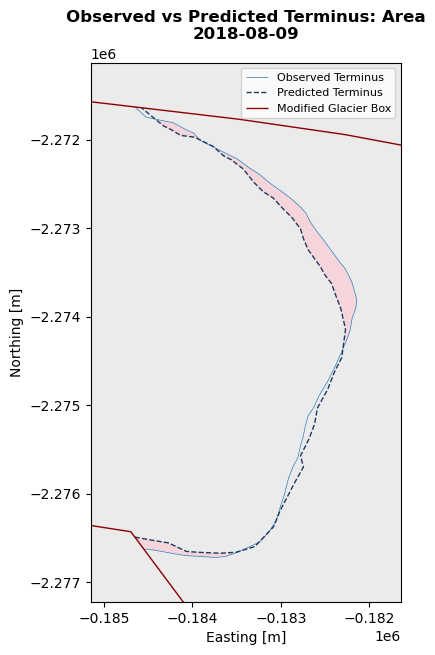

Calving polygon area: 4.87e+05 m²
Sum of sections:      4.87e+05 m²
Bulk area:          4.87e+05 m²


In [38]:
# test 
plot_calving(156)

In [41]:
list(terminus)

['Image_ID',
 'Image_Tile',
 'Date',
 'Flag',
 'Glacier_ID',
 'geometry',
 'intersect_points',
 'vel_at_intersection',
 'vel_up_centerline',
 'Centerline_Length',
 'L',
 'dt_days',
 'dt_years',
 'dL',
 'dLdt',
 'L_expected',
 'expected_minus_observed',
 'calving',
 'calving_magnitude',
 'calving_positive',
 'vx_up_centerline',
 'vy_up_centerline',
 'calving_area_m2',
 'calving_area_km2',
 'calving_sections',
 'calving_sections_areas_km']

In [44]:
terminus

JakobshavnIsbrae_timeseries = terminus[["Date", "geometry", "intersect_points","vel_at_intersection", "vel_up_centerline", "Centerline_Length", "dt_days", "dt_years", "dLdt", "L_expected", "expected_minus_observed", "calving", "calving_positive", "vx_up_centerline", "vy_up_centerline", "calving_area_m2", "calving_area_km2", "calving_sections", "calving_sections_areas_km"]].copy()
output_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/Jakobshavn-Isbrae-CalvingStatistics/JakobshavnIsbrae_data.csv"
JakobshavnIsbrae_timeseries.to_csv(output_path, index=False)

In [34]:
# # calculate calving area for all termini 

# #function for calving area geometry (i.e., between observed/previous line)

# def calving_geometry(i, terminus, box_polygon, ice_point):

#     if i == 0:
#         return None
    
#     else:
#         observed_line = terminus.geometry.iloc[i]
#         previous_line = terminus.geometry.iloc[i - 1]

#         dx = terminus["vx_up_centerline"].iloc[i - 1] * terminus["dt_years"].iloc[i] # d = vt
#         dy = terminus["vy_up_centerline"].iloc[i - 1] * terminus["dt_years"].iloc[i] # d = vt

#         predicted_line = translate(previous_line, xoff=dx, yoff=dy)

#         try: # split the glacier box with observed_line and predicted_line
#             observed_split = split(box_polygon, observed_line)
#             predicted_split = split(box_polygon, predicted_line)

#             observed_polygon = list(observed_split.geoms) #geometry
#             predicted_polygon = list(predicted_split.geoms) #geometry

#             #ensure that observed/predicted glacier is on the correct side (using ice_point) 
#             observed_glacier = [p for p in observed_polygon if p.contains(ice_point)][0]
#             predicted_glacier = [p for p in predicted_polygon if p.contains(ice_point)][0]

#             # derive calving area/polygon using shapely.difference
#             calving_polygon = predicted_glacier.difference(observed_glacier)
#             area_change = calving_polygon.area

#             # split calving area into individual sections
#             if calving_polygon.geom_type == "Polygon":
#                 calving_sections = [calving_polygon]

#             elif calving_polygon.geom_type == "MultiPolygon":
#                 calving_sections = list(calving_polygon.geoms)

#             else:
#                 calving_sections = []

#             #clipped terminus
#             observed_clipped = observed_line.intersection(box_polygon)
#             predicted_clipped = predicted_line.intersection(box_polygon)

#             return {
#                 "observed_line": observed_line, 
#                 "predicted_line": predicted_line, 
#                 "observed_clipped": observed_clipped, 
#                 "predicted_clipped": predicted_clipped, 
#                 "observed_glacier": observed_glacier, 
#                 "predicted_glacier": predicted_glacier, 
#                 "calving_polygon": calving_polygon, 
#                 "calving_sections": calving_sections, 
#                 "calving_area_m2": calving_polygon.area,
#             }

#         except:
#             return None
    

# #  area change function

# def get_area_change(i):

#     i = terminus.index.get_loc(row.name)

#     calving_result = calving_geometry(i, terminus, ji_mod_box_polygon, ice_point)

#     if calving_result is None: 
#         return np.nan

#     return calving_result["calving_area_m2"]

# terminus["calving_area_m2"] = [get_area_change(i) for i in range(len(terminus))]
# terminus["calving_area_km2"] = terminus["calving_area_m2"] / 1e6

# print(terminus["calving_area_km2"].notna().sum())

# #plotting function

# def plot_calving(i):

#     calving_result = calving_geometry(i, terminus, ji_mod_box_polygon, ice_point)

#     if calving_result is None:
#         print("Calving geometry could NOT be calculated :(")
#         return

#     # print date and terminus position
#     print("Date:", terminus["Date"].iloc[i])

#     # calving sections
#     calving_sections = calving_result["calving_sections"]
#     print("Number of calving sections:", len(calving_sections))

#     for section_number, section in enumerate(calving_sections):
#         print(f"{section.area / 1e6:.2e} km²")


# # shorthand plotting properties
#     oprops = dataprops["terminus"]
#     pprops = dataprops["predicted_terminus"]
#     bprops = dataprops["modified_glacier_box"]

#     fig, ax = plt.subplots(figsize=(5, 7), constrained_layout=True)

#     # calving sections
#     for section in calving_sections:
#         gpd.GeoSeries([section],crs=terminus.crs).plot(ax=ax, color="pink", alpha=0.5)

#     # observed terminus
#     gpd.GeoSeries([calving_result["observed_clipped"]], crs=terminus.crs).plot(ax=ax, color=oprops["cmap"](0.7), linewidth=oprops["linewidth"], linestyle=oprops["linestyle"], label=oprops["name"])
#     # predicted terminus
#     gpd.GeoSeries([calving_result["predicted_clipped"]], crs=terminus.crs).plot(ax=ax, color=pprops["color"], linewidth=pprops["linewidth"], linestyle=pprops["linestyle"],label=pprops["name"])
#     # glacier box
#     ji_mod_box.plot(ax=ax, color=bprops["color"], linewidth=bprops["linewidth"], linestyle=bprops["linestyle"], label=bprops["name"])

#     # zoom
#     xmin, ymin, xmax, ymax = calving_result["observed_clipped"].bounds
#     zoom = 500
#     ax.set_xlim(xmin - zoom, xmax + zoom)
#     ax.set_ylim(ymin - zoom, ymax + zoom)
#     ax.set_aspect("equal")

#     # formatting
#     date_title = terminus["Date"].iloc[i].strftime("%Y-%m-%d")
#     ax.set_title(f"Observed vs Predicted Terminus: Area\n{date_title}", fontweight=plotprops["titleweight"])
#     ax.set_xlabel(plotprops["xlabel"])
#     ax.set_ylabel(plotprops["ylabel"])
#     ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
#     ax.set_facecolor(plotprops["facecolor"])
#     ax.legend(fontsize=plotprops["legendsize"])
#     plt.show()

#     print("Calving area:", calving_result["calving_area_m2"] / 1e6, "km²")